Any packages needed put it on top and run first

In [46]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

Initial model assuming constant electricity usage throughout the year

Only annual electricity consumption is available
Therefore, electricity demand is assumed constant on a daily basis throughout 2025 and monthly demand varies only with the number of days (for now)

In [47]:
E_elec = 3.605 # electricity demand in GWh
avg_elec_daily = (E_elec * 1000) / 365

print(f"Daily Electricity usage: {avg_elec_daily} MWh/day")

Daily Electricity usage: 9.876712328767123 MWh/day


In [48]:
months = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
days_in_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

monthly_elec = []

for days in days_in_month:
    monthly_elec.append(avg_elec_daily * days)
monthly_elec

for month, demand in zip(months, monthly_elec):
    print(f"{month}: {demand:.2f} MWh")

print(f"Annual electricity total: {sum(monthly_elec):.2f} MWh")

January: 306.18 MWh
February: 276.55 MWh
March: 306.18 MWh
April: 296.30 MWh
May: 306.18 MWh
June: 296.30 MWh
July: 306.18 MWh
August: 306.18 MWh
September: 296.30 MWh
October: 306.18 MWh
November: 296.30 MWh
December: 306.18 MWh
Annual electricity total: 3605.00 MWh


In [49]:
df = pd.DataFrame({
    "month": months,
    "days": days_in_month,
    "monthly_elec": monthly_elec
})

df

,month,days,monthly_elec
0,January,31,306.178082
1,February,28,276.547945
2,March,31,306.178082
3,April,30,296.301370
4,May,31,306.178082
5,June,30,296.301370
6,July,31,306.178082
7,August,31,306.178082
8,September,30,296.301370
9,October,31,306.178082


Gas modelling with some weather parameters as currently heat is mainly from gas (not electricity).
Winter demand > Summer demand

- Annual Langford gas consumption: 4.651 GWh/year (supplied project data).
- Detailed monthly gas consumption is unavailable, so a synthetic monthly demand
  profile will be developed using Heating Degree Days (HDD).
- A 15°C HDD base temperature is used, following CIBSE weather-data convention.
- Outdoor temperature data is taken from ERA5-Land historical reanalysis for a
  representative Langford Campus location.
- The proportion of gas used for space heating versus year-round/process loads is unknown and will be treated separately as a model assumption/sensitivity.

In [50]:
E_gas = 4.651 # gas demand in GWh
annual_gas_inMWh = E_gas * 1000

lat = 51.3432
long = -2.7780
T_base = 15 

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": lat,
    "longitude": long,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "daily": "temperature_2m_mean",
    "timezone": "Europe/London",
    "models": "era5_land"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

weather_data = response.json()

weather_df = pd.DataFrame({
    "Date": pd.to_datetime(weather_data["daily"]["time"]),
    "T_mean_C": weather_data["daily"]["temperature_2m_mean"]
})

weather_df.head()

len(weather_df)

weather_df["HDD"] = (T_base - weather_df["T_mean_C"]).clip(lower=0)
weather_df.head(10)

annual_hdd = weather_df["HDD"].sum()
print(f"Annual HDD: {annual_hdd:.1f} degree-days")

weather_df["Month"] = weather_df["Date"].dt.month
monthly_hdd = weather_df.groupby("Month")["HDD"].sum()
monthly_hdd

for month_name, hdd in zip(months, monthly_hdd):
    print(f"{month_name}: {hdd:.1f} HDD")



Annual HDD: 1494.0 degree-days
January: 325.3 HDD
February: 250.4 HDD
March: 229.5 HDD
April: 122.4 HDD
May: 34.5 HDD
June: 13.5 HDD
July: 0.0 HDD
August: 0.0 HDD
September: 40.1 HDD
October: 81.0 HDD
November: 166.8 HDD
December: 230.5 HDD


The annual gas demand is separated into a constant daily non-weather-sensitive component and an HDD-dependent heating component. The split is calibrated so that the model reproduces the supplied January gas consumption of 808,515 kWh

In [51]:
jan_gas_mwh = 808_515 / 1000  # kWh -> MWh

jan_days = 31
jan_hdd = monthly_hdd.loc[1]

# Fractions used by the gas-demand model
jan_day_fraction = jan_days / 365
jan_hdd_fraction = jan_hdd / annual_hdd

# Solve for annual non-weather-sensitive gas demand
annual_base_gas_mwh = (
    jan_gas_mwh - annual_gas_inMWh * jan_hdd_fraction
) / (
    jan_day_fraction - jan_hdd_fraction
)

annual_heating_gas_mwh = annual_gas_inMWh - annual_base_gas_mwh

print(f"Annual base gas demand: {annual_base_gas_mwh:.1f} MWh")
print(f"Annual heating gas demand: {annual_heating_gas_mwh:.1f} MWh")
print(f"Base fraction: {annual_base_gas_mwh / annual_gas_inMWh * 100:.1f}%")
print(f"Heating fraction: {annual_heating_gas_mwh / annual_gas_inMWh * 100:.1f}%")

Annual base gas demand: 1537.4 MWh
Annual heating gas demand: 3113.6 MWh
Base fraction: 33.1%
Heating fraction: 66.9%


In [52]:
# Monthly HDD values from 2025 weather data
monthly_hdd_values = monthly_hdd.to_numpy()

monthly_base_gas = []
monthly_heating_gas = []
monthly_total_gas = []

for days, hdd in zip(days_in_month, monthly_hdd_values):

    base_gas = annual_base_gas_mwh * (days / 365)

    heating_gas = annual_heating_gas_mwh * (hdd / annual_hdd)

    total_gas = base_gas + heating_gas

    monthly_base_gas.append(base_gas)
    monthly_heating_gas.append(heating_gas)
    monthly_total_gas.append(total_gas)

for month, gas in zip(months, monthly_total_gas):
    print(f"{month}: {gas:.2f} MWh")

print(f"Annual gas total: {sum(monthly_total_gas):.2f} MWh")

January: 808.51 MWh
February: 639.78 MWh
March: 608.86 MWh
April: 381.45 MWh
May: 202.48 MWh
June: 154.50 MWh
July: 130.58 MWh
August: 130.58 MWh
September: 209.94 MWh
October: 299.38 MWh
November: 473.98 MWh
December: 610.95 MWh
Annual gas total: 4651.00 MWh


In [53]:
df["Gas_Base_MWh"] = monthly_base_gas
df["Gas_Heating_MWh"] = monthly_heating_gas
df["Gas_Total_MWh"] = monthly_total_gas
df

,month,days,monthly_elec,Gas_Base_MWh,Gas_Heating_MWh,Gas_Total_MWh
0,January,31,306.178082,130.577883,677.937117,808.515000
1,February,28,276.547945,117.941314,521.842773,639.784087
2,March,31,306.178082,130.577883,478.286407,608.864291
3,April,30,296.301370,126.365693,255.086084,381.451777
4,May,31,306.178082,130.577883,71.899264,202.477147
5,June,30,296.301370,126.365693,28.134495,154.500188
6,July,31,306.178082,130.577883,0.000000,130.577883
7,August,31,306.178082,130.577883,0.000000,130.577883
8,September,30,296.301370,126.365693,83.569869,209.935562
9,October,31,306.178082,130.577883,168.806967,299.384850


In [54]:
assert len(weather_df) == 365
assert abs(sum(monthly_elec) - 3605) < 0.01
assert abs(sum(monthly_total_gas) - 4651) < 0.01
assert abs(monthly_total_gas[0] - 808.515) < 0.01

print("All baseline model checks passed.")

All baseline model checks passed.


The figures below show the modelled 2025 monthly electricity and gas demand.
Electricity is currently assumed to have a constant daily demand, while gas demand
contains a constant base component and an HDD-dependent heating component.

Index(['month', 'days', 'monthly_elec', 'Gas_Base_MWh', 'Gas_Heating_MWh',
       'Gas_Total_MWh'],
      dtype='str')


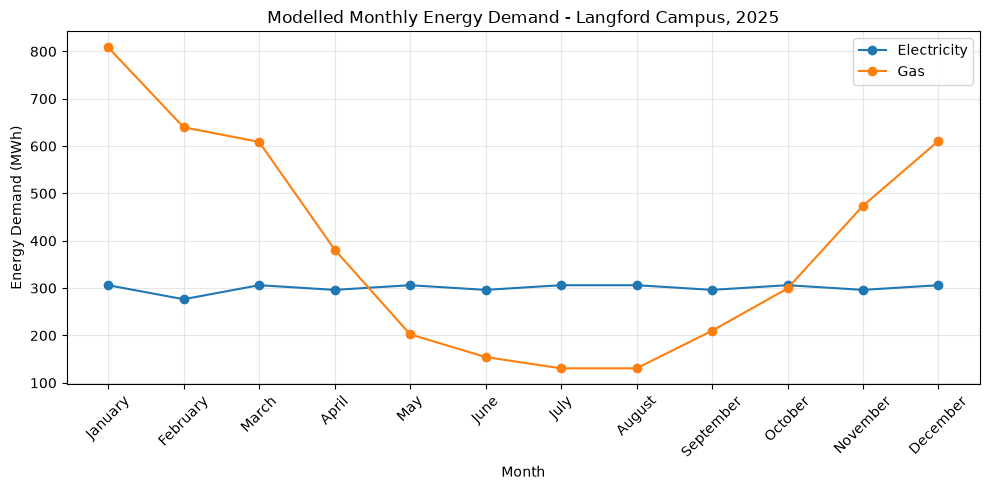

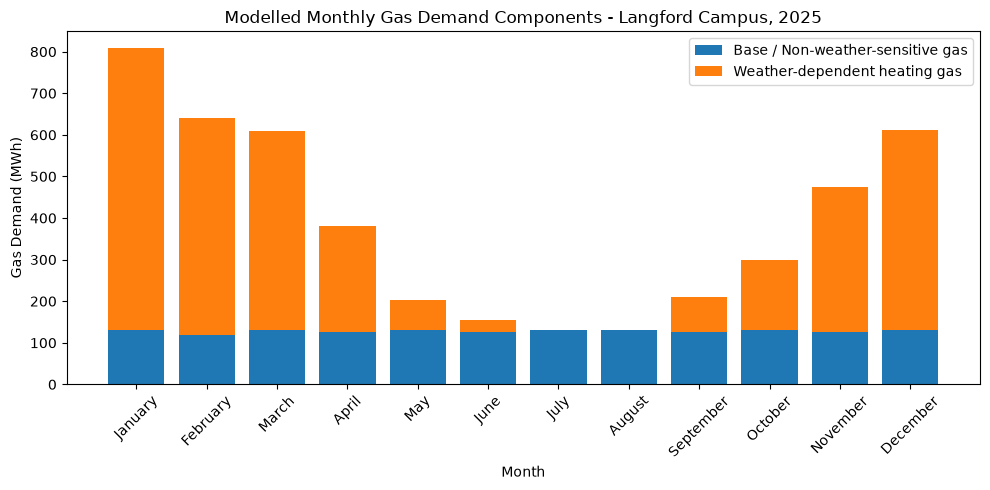

In [55]:
print(df.columns)

plt.figure(figsize=(10, 5))

plt.plot(
    df["month"],
    df["monthly_elec"],
    marker="o",
    label="Electricity"
)

plt.plot(
    df["month"],
    df["Gas_Total_MWh"],
    marker="o",
    label="Gas"
)

plt.xlabel("Month")
plt.ylabel("Energy Demand (MWh)")
plt.title("Modelled Monthly Energy Demand - Langford Campus, 2025")

plt.grid(alpha=0.3)
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.bar(
    df["month"],
    df["Gas_Base_MWh"],
    label="Base / Non-weather-sensitive gas"
)

plt.bar(
    df["month"],
    df["Gas_Heating_MWh"],
    bottom=df["Gas_Base_MWh"],
    label="Weather-dependent heating gas"
)

plt.xlabel("Month")
plt.ylabel("Gas Demand (MWh)")
plt.title("Modelled Monthly Gas Demand Components - Langford Campus, 2025")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()